<a href="https://colab.research.google.com/github/ANKITHATALAPALLY/ANKITHA-T_4NI23CI017_MLLAB_E1/blob/main/MLLAB8_SOM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

File '/content/breast_cancer.csv' not found. Loading breast cancer dataset from sklearn as fallback...
Dataset shape: (569, 30)


,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Preprocessed data shape: (569, 30)
[[0.52103744 0.0226581  0.54598853 0.36373277 0.59375282 0.7920373
  0.70313964 0.73111332 0.68636364 0.60551811 0.35614702 0.12046941
  0.3690336  0.27381126 0.15929565 0.35139844 0.13568182 0.30062512
  0.31164518 0.18304244 0.62077552 0.14152452 0.66831017 0.45069799
  0.60113584 0.61929156 0.56861022 0.91202749 0.59846245 0.41886396]
 [0.64314449 0.27257355 0.61578329 0.50159067 0.28987993 0.18176799
  0.20360825 0.34875746 0.37979798 0.14132266 0.15643672 0.08258929
  0.12444047 0.12565979 0.11938675 0.08132304 0.0469697  0.25383595
  0.08453875 0.0911101  0.60690146 0.30357143 0.53981772 0.43521431
  0.34755332 0.15456336 0.19297125 0.63917526 0.23358959 0.22287813]
 [0.60149557 0.3902604  0.59574321 0.44941676 0.51430893 0.4310165
  0.46251172 0.63568588 0.50959596 0.21124684 0.22962158 0.09430251
  0.18037035 0.16292179 0.15083115 0.2839547  0.09676768 0.38984656
  0.20569032 0.12700551 0.55638563 0.36007463 0.50844166 0.37450845
  0.48358978 

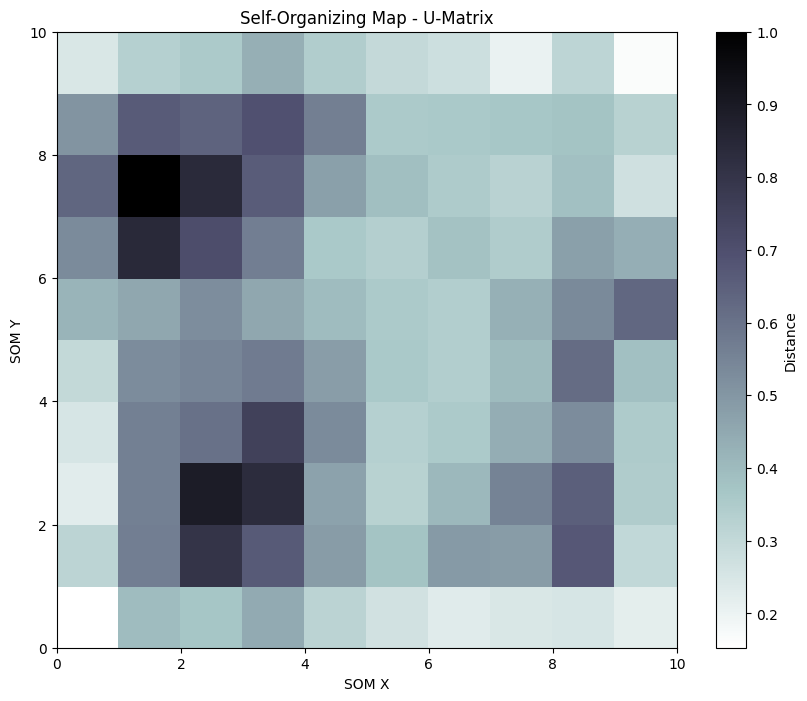

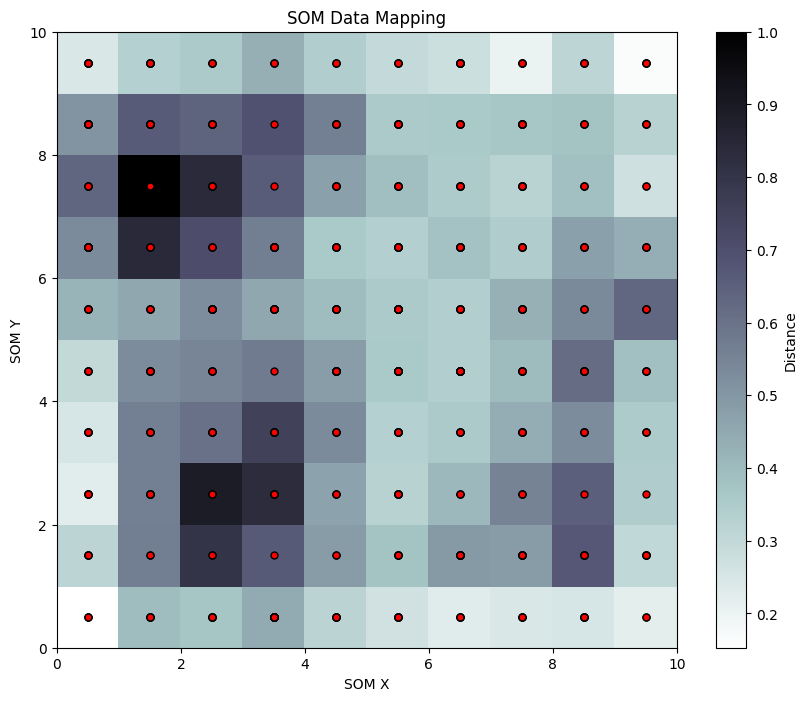

Cluster assignments:
Cluster
0    337
1    131
2    101
Name: count, dtype: int64


,Feature_0,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Feature_8,Feature_9,...,Feature_21,Feature_22,Feature_23,Feature_24,Feature_25,Feature_26,Feature_27,Feature_28,Feature_29,Cluster
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,2
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,2
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,2
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,2


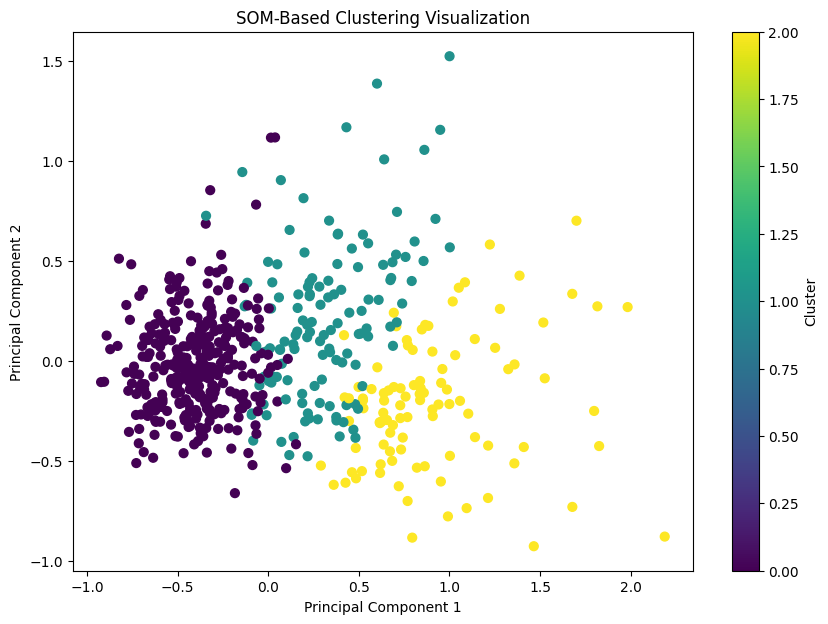

Silhouette Score: 0.2685192036587071


In [2]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.datasets import load_breast_cancer

import warnings
warnings.filterwarnings('ignore')


# Load Breast Cancer Dataset
file_name = '/content/breast_cancer.csv'

try:
    df = pd.read_csv(file_name, header=None)
    print("Dataset loaded successfully from CSV!")
except FileNotFoundError:
    print(f"File '{file_name}' not found. Loading breast cancer dataset from sklearn as fallback...")
    data_obj = load_breast_cancer()
    df = pd.DataFrame(data_obj.data)
    # Add a dummy target column to match typical raw csv structure if needed,
    # but we will only use numerical columns for clustering.

print("Dataset shape:", df.shape)
display(df.head())


# Data Preprocessing

# Handle standard Wisconsin Breast Cancer dataset format if loaded from CSV
if df.shape[1] == 32:
    df = df.drop(columns=[0, 1])
elif df.shape[1] == 31:
    df = df.drop(columns=[0])

# Assign column names
df.columns = [f'Feature_{i}' for i in range(df.shape[1])]

# Remove duplicate rows
df = df.drop_duplicates()

# Select numerical columns
data = df.select_dtypes(include=np.number)

# Handle missing values
data = data.fillna(data.median())

# Normalize data
scaler = MinMaxScaler()
X = scaler.fit_transform(data)

print("Preprocessed data shape:", X.shape)
print(X[:5])


# Install MiniSom
!pip install MiniSom

from minisom import MiniSom


# Define SOM dimensions
som_rows = 10
som_cols = 10

# Initialize SOM
som = MiniSom(
    x=som_rows,
    y=som_cols,
    input_len=X.shape[1],
    sigma=1.0,
    learning_rate=0.5,
    random_seed=42
)

# Initialize weights
som.random_weights_init(X)

# Train SOM
som.train_random(X, num_iteration=1000)

print("SOM training completed!")


# Visualize SOM U-Matrix
plt.figure(figsize=(10, 8))

plt.pcolor(som.distance_map().T, cmap='bone_r')
plt.colorbar(label='Distance')

plt.title("Self-Organizing Map - U-Matrix")
plt.xlabel("SOM X")
plt.ylabel("SOM Y")

plt.show()


# SOM Data Mapping
plt.figure(figsize=(10, 8))

plt.pcolor(som.distance_map().T, cmap='bone_r')
plt.colorbar(label='Distance')

for i, x in enumerate(X):
    w = som.winner(x)

    plt.plot(
        w[0] + 0.5,
        w[1] + 0.5,
        'o',
        markerfacecolor='red',
        markeredgecolor='black',
        markersize=5
    )

plt.title("SOM Data Mapping")
plt.xlabel("SOM X")
plt.ylabel("SOM Y")

plt.show()


# Apply K-Means Clustering on SOM Weights

# Get trained SOM weights
weights = som.get_weights()

# Reshape weights into a 2D array
weights_reshaped = weights.reshape(-1, X.shape[1])

# Apply K-Means
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans.fit(weights_reshaped)


# Assign cluster labels using BMU
cluster_labels = []

for x in X:
    winner = som.winner(x)

    neuron_index = winner[0] * som_cols + winner[1]

    cluster_labels.append(kmeans.labels_[neuron_index])


# Add cluster labels to dataframe
df['Cluster'] = cluster_labels

print("Cluster assignments:")
print(df['Cluster'].value_counts().sort_index())

display(df.head())


# PCA Visualization
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels,
    cmap='viridis',
    s=40
)

plt.title("SOM-Based Clustering Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.colorbar(label="Cluster")

plt.show()


# Evaluate using Silhouette Score
score = silhouette_score(X, cluster_labels)

print("Silhouette Score:", score)